## Initial TG Testing
A quick initial look at output from testing at Tony Grove.

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
tg_output = xr.open_dataset('C:/Users/clmbn/NMT_PhD/data/output/TG_testing/20150101.land_daily.nc')


In [3]:
tg_output

<xarray.Dataset> Size: 650kB
Dimensions:                  (grid_index: 1, time: 1826, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 15kB 2015-01-01 12:00:00 ... 2019-...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -111.6
  * lonb                     (lonb) float64 16B -112.1 -111.1
  * lat                      (lat) float64 8B 41.89
  * latb                     (latb) float64 16B 41.39 42.39
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float64 8B ...
    geolat_t                 (grid_index) float64 8B ...
Data variables: (12/56)
    fco2                     (time, grid_index) float32 7kB ...
    t_ref                    (time, grid_index) float32 7kB ...
    co2_mol_flux             (time, grid_index) float32 7kB ...
    co2_mol_flux1            (time, grid_index) float32 7kB ...
    btot                     (time, grid_index) float32 7kB ...
    Ctot                     (time, grid_index) float32 7kB ...
    ...                       ...
    drydep_md                (time, grid_index) float32 7kB ...
    drydep_om                (time, grid_index) float32 7kB ...
    average_T1               (time) datetime64[ns] 15kB ...
    average_T2               (time) datetime64[ns] 15kB ...
    average_DT               (time) timedelta64[ns] 15kB ...
    time_bnds                (time, nv) object 29kB ...
Attributes:
    filename:          land_daily.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

Try extracting some data to dataframe

In [4]:
snow_data = tg_output[['snow','snow_depth','snow_density']].isel(grid_index=0).to_dataframe()

In [5]:
snow_data

,snow,snow_depth,snow_density,grid_index,geolon_t,geolat_t
time,,,,,,
2015-01-01 12:00:00,0.000000,0.000000,0.0,0.0,-111.57,41.89
2015-01-02 12:00:00,0.000000,0.000000,0.0,0.0,-111.57,41.89
2015-01-03 12:00:00,0.000000,0.000000,0.0,0.0,-111.57,41.89
2015-01-04 12:00:00,0.000000,0.000000,0.0,0.0,-111.57,41.89
2015-01-05 12:00:00,0.000000,0.000000,0.0,0.0,-111.57,41.89
...,...,...,...,...,...,...
2019-12-27 12:00:00,69.613091,0.278452,0.0,0.0,-111.57,41.89
2019-12-28 12:00:00,69.635254,0.278541,0.0,0.0,-111.57,41.89
2019-12-29 12:00:00,69.978111,0.279912,0.0,0.0,-111.57,41.89


In [7]:
snow_data.index

CFTimeIndex([2015-01-01 12:00:00, 2015-01-02 12:00:00, 2015-01-03 12:00:00,
             2015-01-04 12:00:00, 2015-01-05 12:00:00, 2015-01-06 12:00:00,
             2015-01-07 12:00:00, 2015-01-08 12:00:00, 2015-01-09 12:00:00,
             2015-01-10 12:00:00,
             ...
             2019-12-22 12:00:00, 2019-12-23 12:00:00, 2019-12-24 12:00:00,
             2019-12-25 12:00:00, 2019-12-26 12:00:00, 2019-12-27 12:00:00,
             2019-12-28 12:00:00, 2019-12-29 12:00:00, 2019-12-30 12:00:00,
             2019-12-31 12:00:00],
            dtype='object', length=1826, calendar='julian', freq='D')

In [10]:
# Convert the index to a datetime index
snow_data.index = snow_data.index.to_datetimeindex()

C:\Users\clmbn\AppData\Local\Temp\ipykernel_15344\1143443307.py:2: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  snow_data.index = snow_data.index.to_datetimeindex()


<Axes: >

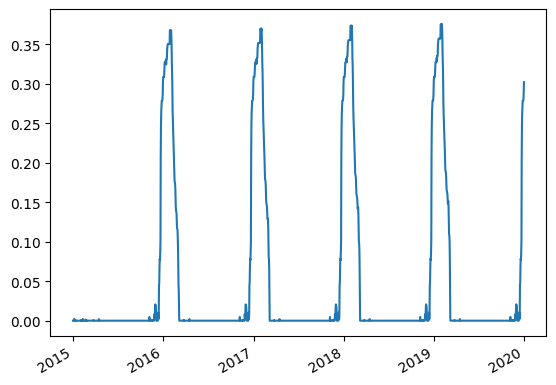

In [12]:
snow_data['snow_depth'].plot()